In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path("model_files").resolve()))

In [2]:
%load_ext autoreload
%autoreload 2
import json
import random

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import torch
from data import build_sequences, collate
from run import load_split, make_model, move_transactions, read_config

from xai_methods.ig import run_ig_segment

/Applications/miniforge3/envs/Timeseries/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1115 18:59:53.220000 39870 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


In [3]:
from pathlib import Path

In [4]:
HERE = Path().resolve()
DEFAULT_CHECKPOINT = HERE / "model_files" / "checkpoint" / "best.pt"
DEFAULT_CHECKPOINT_CONFIG = HERE / "model_files" / "checkpoint" / "config.yaml"
DEFAULT_TRAIN_CONFIG = HERE / "config.json"

In [5]:
checkpoint = DEFAULT_CHECKPOINT
config = read_config(DEFAULT_CHECKPOINT_CONFIG)

In [9]:
# cборка модели
seed = config["train"]["seed"]
saved = torch.load(
    HERE / "model_files" / "checkpoint" / "best.pt", map_location="cpu", weights_only=True
)
model = make_model(
    config, json.loads((HERE / "model_files" / "data" / "metadata.json").read_text())
)
model.load_state_dict(saved["model_state"], strict=True)
device = torch.device("mps") if torch.mps.is_available() else torch.device("cpu")
model.to(device)
model.eval()  # устанавливаем в режим инфириенса и собираем градиенты.
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 0), got 1. This may result in unexpected behavior.


In [10]:
# специальная функция для того, чтобы загружать кастомные ряды для IG
def create_batch_one_client(client, metadata, keys, device):
    cur = build_sequences(client.to_pandas(), metadata, keys)
    batch = collate(list(cur.values()), keys)
    return model.encode(move_transactions(batch, device))

In [11]:
df = pl.scan_parquet("model_files/data/transactions.parquet").collect(engine="streaming")

In [12]:
batch = 100
split = "val"
metadata = json.loads((HERE / "model_files" / "data" / "metadata.json").read_text())
evaluation = load_split(HERE / "model_files" / "data", split, config, metadata, None)
keys = config["model"]["transaction_keys"]

In [13]:
batch_args = {"metadata": metadata, "keys": keys, "device": device}

In [14]:
def score_model(model, client, batch_args):
    model.eval()
    model.zero_grad()
    cur = build_sequences(
        client.to_pandas(), batch_args["metadata"], batch_args["keys"], require_grad=True
    )

    batch = collate(list(cur.values()), batch_args["keys"])
    embed = model.encode(move_transactions(batch, batch_args["device"]))
    logits = model.classifier(embed)
    probab = torch.softmax(logits, dim=-1)
    return probab[:, 1]

In [15]:
choosed_client = "2320"
window_size = 10
key = "amount"

get_attrs_window, attr = run_ig_segment(
    model, df, choosed_client, key, None, batch_args, None, 1000, True
)
# ig_describe_segment(df, choosed_client, get_attrs_window, key)

Step of ig is: 0/1: 100%|██████████| 1/1 [00:16<00:00, 16.64s/it]


<BarContainer object of 35 artists>

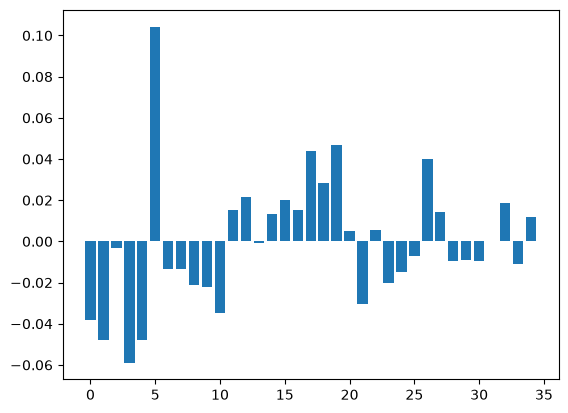

In [16]:
# plt.imshow(attr)
plt.bar(range(0, attr.shape[1]), attr[0])

#########TIMING#############

In [17]:
from xai_methods.ig import get_client

df_client = get_client(df, choosed_client)

In [42]:
def timing(
    n_segments,
    model,
    df,
    client_id,
    key,
    batch_args,
    len_min=None,
    len_max=None,
    IG_PRECISION=50,
    seed=42,
):
    torch.manual_seed(seed)
    df_client = get_client(df, client_id)

    alphas = torch.linspace(0, 1, IG_PRECISION, device=batch_args["device"], dtype=torch.float32)

    x_input = df_client[key].to_torch().to(device=batch_args["device"], dtype=torch.float32)

    # отсоеднияем, т.к. мы используем здесь маскированную часть по которой градиенты не текут.
    x_fixed = x_input.detach()
    x_inter = alphas[:, None] * x_input[None, :]

    T = len(df_client[key])
    N = IG_PRECISION

    if len_min is None:
        len_min = 1
    if len_max is None:
        len_max = T

    seg_lens = torch.randint(len_min, len_max + 1, (N, n_segments), device=device)

    t_starts = (torch.rand(N, n_segments, device=device) * (T - seg_lens + 1)).long()
    time_mask = torch.ones_like(x_inter)

    time_mask = torch.ones((N, T), device=device)

    for s in range(n_segments):
        max_len = int(seg_lens[:, s].max())

        indices = t_starts[:, s, None] + torch.arange(max_len, device=device)[None, :]

        valid = indices < (t_starts[:, s] + seg_lens[:, s])[:, None]

        sample_idx, offset_idx = valid.nonzero(as_tuple=True)
        time_idx = indices[sample_idx, offset_idx]

        time_mask[sample_idx, time_idx] = 0

    masked_inputs = time_mask * x_inter + (1 - time_mask) * x_fixed
    masked_inputs.requires_grad_(True)

    grads = torch.zeros((N, T))
    for rep in range(N):
        df_new = df_client
        # df_new[keys] = masked_inputs[rep].detach().to('cpu')
        cur = build_sequences(
            df_new.to_pandas(), batch_args["metadata"], batch_args["keys"], require_grad=True
        )
        batch = collate(list(cur.values()), batch_args["keys"])
        batch["transactions"][key] = masked_inputs[rep][None, :]

        embed = model.encode(move_transactions(batch, batch_args["device"]))
        logits = model.classifier(embed)

        probab = torch.softmax(logits, dim=-1)

        grad = torch.autograd.grad(
            inputs=batch["transactions"][key], outputs=probab[:, 1].sum(), allow_unused=True
        )

        # print(grad[0])
        grads[rep] = grad[0]

    avg_grad = (grads[:-1] + grads[1:]) / torch.scalar_tensor(2.0, dtype=torch.float32)
    avg_grads = torch.mean(avg_grad, dim=0) * df_client[key].to_torch()

    return avg_grads

<BarContainer object of 35 artists>

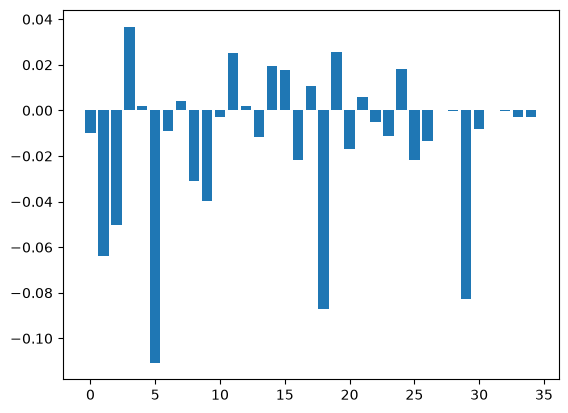

In [44]:
attr = timing(5, model, df, choosed_client, key, batch_args)

attr_1 = timing(5, model, df, choosed_client, key, batch_args)
plt.bar([x for x in range(attr.shape[0])], attr)